load

In [1]:
import sys
import os
sys.path.append(os.path.abspath(".."))

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

In [2]:
# Load dataset
df = pd.read_csv("../data/processed/dataset_final.csv")
df = df.sort_values("date")

# Buang date
df_model = df.drop(columns=["date"])

In [3]:
import joblib

model = tf.keras.models.load_model("../model/model_multi/lstm_multi.keras")
scaler = joblib.load("../model/model_multi/scaler_multi.save")

In [4]:
model.output_shape

(None, 5)

forecast

In [5]:
future_steps = 252
all_predictions = []

current_window = scaled_full[-window_size:]
current_window = current_window.reshape(1, window_size, df_model.shape[1])

for year in range(10):

    yearly_predictions = []

    for _ in range(future_steps):
        next_pred = model.predict(current_window, verbose=0)
        yearly_predictions.append(next_pred[0])

        next_input = current_window[0,1:]
        next_input = np.vstack((next_input, next_pred[0]))
        current_window = next_input.reshape(1, window_size, df_model.shape[1])

    yearly_predictions = np.array(yearly_predictions)

    # re-anchor ke nilai terakhir real (hindari drift collapse)
    scaled_full = np.vstack((scaled_full, yearly_predictions))
    current_window = scaled_full[-window_size:]
    current_window = current_window.reshape(1, window_size, df_model.shape[1])

    all_predictions.extend(yearly_predictions)

future_predictions = np.array(all_predictions)
future_real = scaler.inverse_transform(future_predictions)

NameError: name 'scaled_full' is not defined

In [ ]:
future_real = scaler.inverse_transform(future_predictions)

plot

In [ ]:
# Ambil tanggal terakhir historis
last_date = pd.to_datetime(df["date"]).iloc[-1]

# 252 hari kerja x 10 tahun
future_dates = pd.bdate_range(
    start=last_date,
    periods=len(future_real)+1
)[1:]

In [ ]:
future_ihsg = future_real[:, 0]

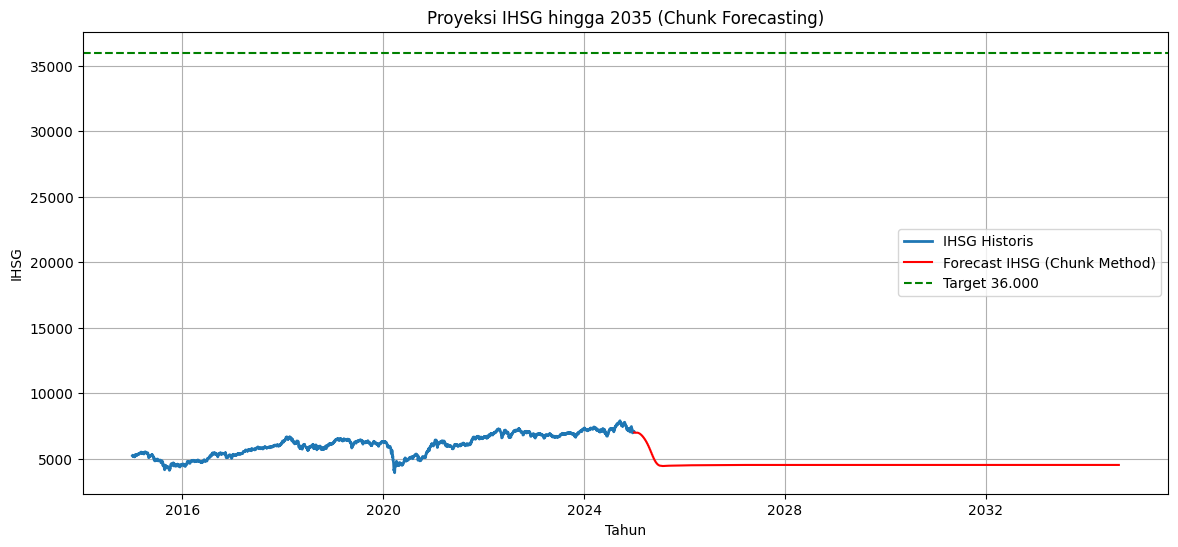

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14,6))

# Historis
plt.plot(
    pd.to_datetime(df["date"]),
    df["ihsg"],
    label="IHSG Historis",
    linewidth=2
)

# Forecast 10 Tahun
plt.plot(
    future_dates,
    future_ihsg,
    color="red",
    label="Forecast IHSG (Chunk Method)"
)

# Target 36.000
plt.axhline(
    y=36000,
    color="green",
    linestyle="--",
    label="Target 36.000"
)

plt.title("Proyeksi IHSG hingga 2035 (Chunk Forecasting)")
plt.xlabel("Tahun")
plt.ylabel("IHSG")
plt.legend()
plt.grid(True)
plt.show()

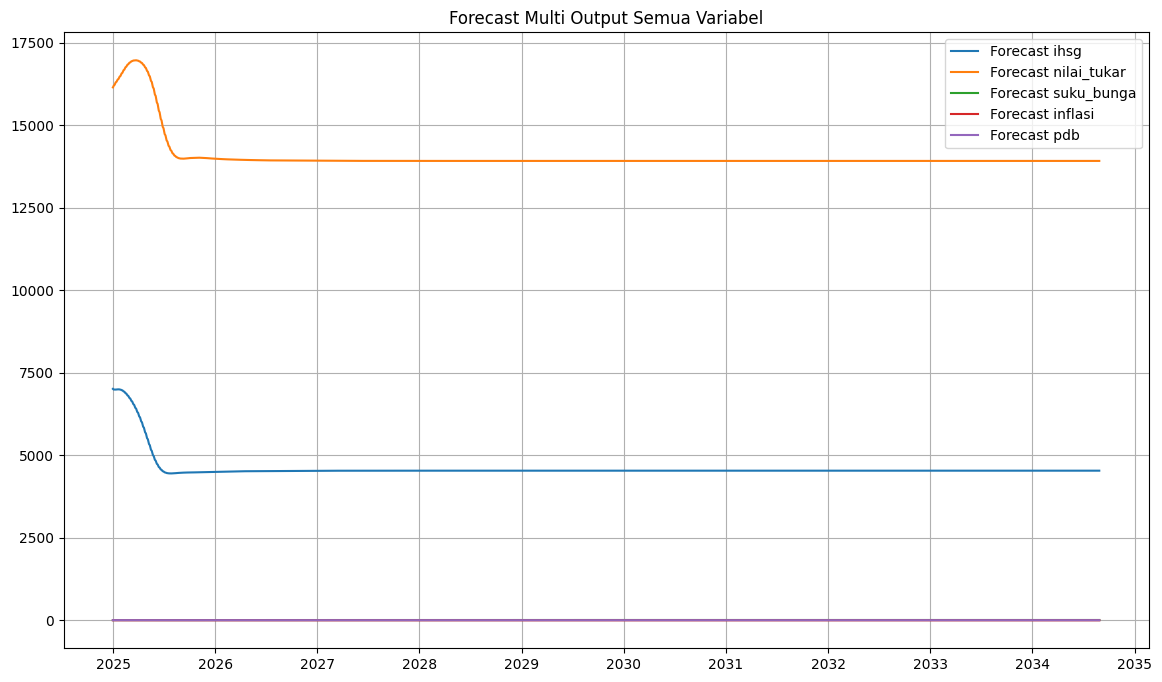

In [ ]:
columns = ["ihsg", "nilai_tukar", "suku_bunga", "inflasi", "pdb"]

plt.figure(figsize=(14,8))

for i, col in enumerate(columns):
    plt.plot(
        future_dates,
        future_real[:, i],
        label=f"Forecast {col}"
    )

plt.title("Forecast Multi Output Semua Variabel")
plt.legend()
plt.grid(True)
plt.show()
